In this homework, we study further about the logistic regression and will implement the logistic regression with (1) PyTorch API and (2) manual gradient descent. For the implementation we will consider a dataset consisting of 2-dimensional input features and binary class labels, and you will be asked to implement machine learning classifiers. Total 15 pts.

# Derivation of loss gradient [3 points]

- Complete the following derivation: find the derivatives of the loss term w.r.t. $\pmb{\theta}$:

Consider the binary cross-entropy (BCE) loss:
$$\ell(\pmb{\theta}) = -[y \log( h(\pmb{\theta}^{\mathsf T}\pmb{x})) + (1-y) \log ( 1- h(\pmb{\theta}^{\mathsf T}\pmb{x}))]$$
where $$h(z) = \frac{1}{1 + e^{-z} },\quad \pmb{\theta} = \begin{bmatrix} \theta_0 \\ \theta_1 \\ \theta_2 \end{bmatrix}, \quad\text{and}\quad \pmb{x} = \begin{bmatrix} 1 \\ x_1 \\ x_2, \end{bmatrix}.$$

Now we will write down the analytical expression of the derivative of $\ell(\pmb{\theta})$ w.r.t. $\pmb{\theta}$:

\begin{equation*}
    \nabla_{\pmb{\theta}} \ell (\pmb{\theta}) = \begin{bmatrix}
    \frac{\partial \ell (\pmb{\theta})}{\partial \theta_0}\\
    \frac{\partial \ell (\pmb{\theta})}{\partial \theta_1}\\
    \frac{\partial \ell (\pmb{\theta})}{\partial \theta_2}
    \end{bmatrix} = \text{[Your answer]}
\end{equation*}
Write down a step-by-step derivation. You will have to use the following mathematical facts. In every step of the derivation, explain how you used these mathematical facts.

  - use the chain-rule: $\frac{\mathrm d y}{\mathrm d x} = \frac{\mathrm d y}{\mathrm d z}\frac{\mathrm d z}{\mathrm d x}$
  
  - derivative of the log function: $\frac{\mathrm d \log (x)}{\mathrm d  x} = \frac{1}{x}$
  
  - derivative of $h(x) = \frac{1}{1 + e^{-x}}$: $\frac{\mathrm d h(x)}{\mathrm d x } = h(x) (1-h(x))$  



# Implementing the logistic regression using PyTorch API

You will implement the logistic regression algorithm by leveraing the PyTorch API. You will need PyTorch, NumPy, Matplotlib installed in your system.

In [ ]:
import sys; sys.path.append('../..') ; sys.path.append('..') ; from my_utils import *

import torch
import torch.nn as nn
import torch.utils.data as data
# dummy trainloader
trainloader = data.DataLoader(data.TensorDataset(torch.Tensor(1), torch.Tensor(1)), batch_size=1, shuffle=True)
device = torch.device('cpu')

import matplotlib.pyplot as plt

/Users/klee263/venv-nsindy/lib/python3.7/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Next, we set a random seed for reproducibility.

In [ ]:
import numpy as np
import random

seed = 0
np.random.seed(seed)
torch.random.manual_seed(seed)
random.seed(seed)

## Part 2. Logistic regression using PyTorch [6 points]
### Two Gaussian blobs

The cell below generates **2,048 observations: 1,024 per class**. `X` has shape `(N, 2)` and stores the two raw features; `y` has shape `(N,)` and stores integer labels. The initial plot uses the **true labels**.

Keep this same `X` and `y` for Parts 2 and 3. Do not append a column of ones to `X`: the model's linear layer will provide the bias corresponding to $\theta_0$.

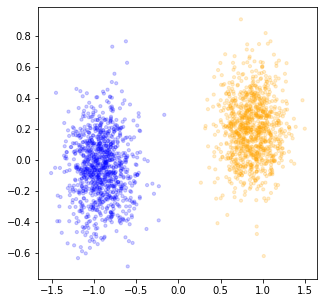

In [ ]:
X, y = sample_gaussian()
fig, ax = plt.subplots(1,1, figsize=(5,5))
plot_scatter(ax, X, y)



### 2.1 Define the model [2 points]

Complete `Model` below. Use one `nn.Linear` layer with two inputs, one output, and a bias. **Name it `self.linear_layer`** because Part 3 accesses its parameters by that name. Apply a sigmoid in `forward` so that the model returns class-1 probabilities.

- Input shape: `(N, 2)`.
- Output shape: `(N, 1)`.
- Parameter mapping: `linear_layer.bias[0]` is $\theta_0$; `linear_layer.weight[0, 0]` and `linear_layer.weight[0, 1]` are $\theta_1$ and $\theta_2$.

Do not add hidden layers or additional trainable parameters.

If you are new to PyTorch, looking at this blog post would be very helpful: https://machinelearningmastery.com/building-a-logistic-regression-classifier-in-pytorch/

In [ ]:
class Model(nn.Module):
    def __init__(self,device="cpu"):
        super(Model, self).__init__()

    def forward(self, x):
        # [TODO] your code
        return y

In [ ]:
model = Model().to(device)

We will be using AdamW optimizer.

In [ ]:
import torch.optim as optim
optimizer = optim.AdamW(model.parameters(), lr=1e-2, weight_decay=1e-6)

### 2.2 Train with automatic differentiation [2 points]

Complete the loss calculation using `nn.BCELoss` with mean reduction. This loss expects **probabilities** and floating-point targets of the **same shape**. For example, you may use predictions of shape `(N,)` via `.squeeze(-1)` and targets `y.float()`. Avoid accidentally broadcasting `(N, 1)` predictions against `(N,)` targets.

Use the provided AdamW optimizer and run **2,000 full-batch iterations**. Each iteration must clear previous gradients, compute predictions and the mean BCE loss, backpropagate, and update the parameters. The loop skeleton supplies the optimizer steps; complete the marked section. Print the loss at the indicated intervals to monitor training.

Because the model already applies a sigmoid, use `nn.BCELoss` here, rather than a loss that expects raw logits.


In [ ]:
for itr in range(1, 2001):
    optimizer.zero_grad()
    yh = model(X) # forward pass
    # compute loss # [TODO] your code
    loss.backward() # backward pass
    optimizer.step()

1 0.43376824259757996
2 0.4296470284461975
3 0.42557501792907715
4 0.42155301570892334
5 0.41758137941360474
6 0.4136607050895691
7 0.4097912907600403
8 0.4059736430644989
9 0.40220803022384644
10 0.3984944820404053
11 0.3948332667350769
12 0.39122438430786133
13 0.38766786456108093
14 0.38416340947151184
15 0.38071104884147644
16 0.3773104250431061
17 0.37396112084388733
18 0.3706628084182739
19 0.3674149811267853
20 0.364217072725296
21 0.3610684275627136
22 0.35796844959259033
23 0.35491639375686646
24 0.35191136598587036
25 0.34895262122154236
26 0.34603938460350037
27 0.3431706130504608
28 0.3403454124927521
29 0.33756282925605774
30 0.3348219394683838
31 0.33212172985076904
32 0.3294612169265747
33 0.3268393576145172
34 0.32425519824028015
35 0.32170775532722473
36 0.31919604539871216
37 0.3167191743850708
38 0.3142760992050171
39 0.3118659257888794
40 0.30948781967163086
41 0.30714085698127747
42 0.30482426285743713
43 0.3025371730327606
44 0.30027884244918823
45 0.2980485260486

667 0.03399362042546272
668 0.03393004089593887
669 0.03386665880680084
670 0.033803462982177734
671 0.03374047204852104
672 0.033677663654088974
673 0.033615052700042725
674 0.0335526242852211
675 0.033490389585494995
676 0.03342834487557411
677 0.03336648643016815
678 0.033304814249277115
679 0.033243328332901
680 0.03318202495574951
681 0.033120907843112946
682 0.0330599769949913
683 0.032999228686094284
684 0.03293866664171219
685 0.03287827968597412
686 0.03281807899475098
687 0.03275805339217186
688 0.032698214054107666
689 0.0326385460793972
690 0.03257906064391136
691 0.03251974657177925
692 0.032460615038871765
693 0.03240165486931801
694 0.03234286606311798
695 0.03228425234556198
696 0.03222581371665001
697 0.032167546451091766
698 0.03210946172475815
699 0.032051533460617065
700 0.03199378401041031
701 0.031936198472976685
702 0.03187878429889679
703 0.031821541488170624
704 0.03176446259021759
705 0.031707555055618286
706 0.031650807708501816
707 0.031594231724739075
708 0

1022 0.01949474588036537
1023 0.01946890354156494
1024 0.019443117082118988
1025 0.019417384639382362
1026 0.019391706213355064
1027 0.019366079941391945
1028 0.01934051141142845
1029 0.019314996898174286
1030 0.019289530813694
1031 0.01926412060856819
1032 0.01923876442015171
1033 0.019213465973734856
1034 0.01918821409344673
1035 0.019163018092513084
1036 0.019137876108288765
1037 0.019112788140773773
1038 0.019087746739387512
1039 0.019062761217355728
1040 0.01903783157467842
1041 0.019012954086065292
1042 0.018988121300935745
1043 0.018963348120450974
1044 0.018938623368740082
1045 0.01891394890844822
1046 0.018889326602220535
1047 0.01886475458741188
1048 0.018840234726667404
1049 0.018815765157341957
1050 0.01879134774208069
1051 0.0187669787555933
1052 0.01874266006052494
1053 0.01871839538216591
1054 0.018694177269935608
1055 0.018670009449124336
1056 0.018645895645022392
1057 0.01862182654440403
1058 0.018597809597849846
1059 0.018573841080069542
1060 0.018549922853708267
1061

1380 0.012822835706174374
1381 0.012809510342776775
1382 0.012796211056411266
1383 0.012782929465174675
1384 0.012769670225679874
1385 0.012756437063217163
1386 0.01274321973323822
1387 0.012730027548968792
1388 0.012716852128505707
1389 0.012703700922429562
1390 0.012690574862062931
1391 0.012677464634180069
1392 0.012664377689361572
1393 0.012651310302317142
1394 0.012638263404369354
1395 0.012625242583453655
1396 0.0126122385263443
1397 0.01259925588965416
1398 0.012586293742060661
1399 0.012573352083563805
1400 0.012560429982841015
1401 0.012547530233860016
1402 0.012534650042653084
1403 0.012521790340542793
1404 0.012508955784142017
1405 0.012496134266257286
1406 0.012483341619372368
1407 0.012470562011003494
1408 0.01245780661702156
1409 0.01244506798684597
1410 0.01243235357105732
1411 0.012419656850397587
1412 0.01240698155015707
1413 0.01239432767033577
1414 0.012381691485643387
1415 0.012369079515337944
1416 0.012356484308838844
1417 0.012343909591436386
1418 0.01233135256916

1738 0.009138200432062149
1739 0.009130298160016537
1740 0.00912240520119667
1741 0.009114522486925125
1742 0.009106649085879326
1743 0.009098786860704422
1744 0.009090935811400414
1745 0.009083094075322151
1746 0.009075261652469635
1747 0.009067442268133163
1748 0.00905962847173214
1749 0.00905182957649231
1750 0.009044038131833076
1751 0.00903625600039959
1752 0.009028486907482147
1753 0.009020727127790451
1754 0.009012976661324501
1755 0.009005235508084297
1756 0.008997506462037563
1757 0.008989785797894001
1758 0.00898207537829876
1759 0.008974375203251839
1760 0.008966685272753239
1761 0.008959006518125534
1762 0.008951336145401001
1763 0.008943676017224789
1764 0.008936027064919472
1765 0.008928386494517326
1766 0.008920757099986076
1767 0.008913135156035423
1768 0.008905526250600815
1769 0.008897924795746803
1770 0.008890334516763687
1771 0.008882753551006317
1772 0.008875181898474693
1773 0.008867621421813965
1774 0.008860069327056408
1775 0.008852529339492321
1776 0.0088449968

### 2.3 Plot predictions and the decision boundary [2 points]

Use the trained `model` to predict labels for all observations in `X`: assign class 1 when $p\geq 0.5$, and class 0 otherwise.

Create one plot containing:

1. The training points colored by their **predicted labels** (not `y`). You may reuse `plot_scatter`.
2. The learned $p=0.5$ decision boundary over the data range. You may plot the line $\theta_0+\theta_1 x_1+\theta_2 x_2=0$ or evaluate probabilities on a two-dimensional grid and draw the 0.5 contour. If you solve the line equation for one coordinate, handle a zero or nearly zero denominator.

Perform prediction and plotting under `torch.no_grad()`. The reference below illustrates the expected plot content; your colors and exact learned boundary need not match it.

See the example below.

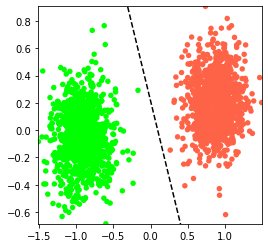

torch.Size([2048, 2])


In [ ]:
with torch.no_grad():
    fig = plt.figure(figsize=(4,4))
    # [TODO] your code
    plt.show()

## Part 3. Logistic regression using manual gradient descent [7 points]

Use the same model architecture and dataset, but train a **new model from scratch**. This part uses ordinary full-batch gradient descent with learning rate $10^{-2}$ for 2,000 iterations.

Compute the gradients from your derivation in Part 1 and update the parameters yourself. **Do not use** `.backward()`, `torch.autograd.grad`, any PyTorch optimizer, or gradients read from `.grad` in this part. PyTorch tensor operations and `torch.no_grad()` are allowed. For the loss, implement the formula yourself; do not call built-in BCE loss functions.

The cell below creates `model2`. Its weights have shape `(1, 2)` and its bias has shape `(1,)`. Re-run this cell if you want to restart manual training. Do not copy the trained parameters from Part 2.

Part 2 uses AdamW with a small weight decay; Part 3 uses unregularized gradient descent on mean BCE. Their parameter values, loss trajectories, and decision boundaries are not required to match exactly.


In [ ]:
model2 = Model().to(device)

You can access to the model parameters as follows.

In [ ]:
print(model2.linear_layer.weight)
print(model2.linear_layer.bias)

Parameter containing:
tensor([[ 0.3741, -0.7029]], requires_grad=True)
Parameter containing:
tensor([-0.3931], requires_grad=True)


### 3.1 Implement binary cross-entropy [2 points]

Complete `binary_cross_entropy(y_true, y_pred)` using the BCE formula from Part 1, averaged over all $N$ observations. Use `torch.log` and tensor operations. Both arguments should be floating-point tensors of shape `(N,)`; return a **scalar tensor**, not a Python float or a vector of per-observation losses.

The supplied clipping step keeps probabilities away from 0 and 1 before taking logarithms. Keep `epsilon=1e-12`; the additional dtype-aware guard ensures that the upper bound is representable below 1 in float32. Clipping is a numerical safeguard for evaluating the loss. In Part 3.2, use the analytical logistic BCE gradient derived in Part 1 with the model's original probabilities; do not differentiate the clipping operation.


In [ ]:
def binary_cross_entropy(y_true, y_pred, epsilon=1e-12):
    """
    Compute the binary cross-entropy loss.

    Parameters:
    y_true (torch array): Ground truth labels (0 or 1).
    y_pred (torch array): Predicted probabilities (between 0 and 1).
    epsilon (float): Small value to prevent log(0). [NOTE] do not change this

    Returns:
    float: Binary cross-entropy loss.
    """
    # Clip predictions to avoid log(0) issues
    y_pred = torch.clip(y_pred, epsilon, 1 - epsilon)

    # Compute BCE loss
    loss = #[TODO]
    return loss

### 3.2 Implement the manual training loop [3 points]

Complete the loop below. In each iteration:

1. Compute class-1 probabilities for the entire training set using `model2`.
2. Evaluate the mean loss by calling `binary_cross_entropy(y.float(), yh)` in this order: **true labels first, predicted probabilities second**.
3. Compute gradients with respect to both weights and the bias from your Part 1 expression for the **mean** loss. Include the averaging factor over observations. Compute all gradients using the current predictions, before changing any parameter.
4. Subtract the learning rate times each gradient from the corresponding parameter. You may update the weights together or update the three scalar parameters individually. Keep update shapes consistent with the parameter shapes.

The supplied `torch.no_grad()` context disables automatic gradient tracking and permits in-place parameter updates. The printed loss is the value computed before that iteration's update. Use these values to check that training is making progress.

for loop:

    y-prediction = model2(input)
    
    loss = binary_cross_entropy(y-prediction, y-ground truth)
    
    grad-theta0 = compute gradient of loss w.r.t. theta0
    grad-theta1 = compute gradient of loss w.r.t. theta1
    grad-theta2 = compute gradient of loss w.r.t. theta2
    
    #update
    theta0 -= learning_rate * grad-theta0
    theta1 -= learning_rate * grad-theta1
    theta2 -= learning_rate * grad-theta2

In [ ]:
learning_rate = 1e-2
for t in range(2000):
    # Forward pass: compute predicted y
    yh = model2(X)

    # Compute and print loss
    loss = binary_cross_entropy(y.float(),yh.squeeze()) #np.square(y_pred - y).sum()
    print(loss)

    # [TODO] your code: iteratively update the model parameters
    # The model parameters theta_0, theta_1, theta_2 can be updated individually
    # by (1) computing the gradient using the analytical expression you obtained from the part 1 of the homework
    # by (2) updating the model parameters into the "DESCENDING" direction by the step size (that is, learning rate)

tensor(0.6050, grad_fn=<NegBackward0>)
tensor(0.6031, grad_fn=<NegBackward0>)
tensor(0.6012, grad_fn=<NegBackward0>)
tensor(0.5994, grad_fn=<NegBackward0>)
tensor(0.5975, grad_fn=<NegBackward0>)
tensor(0.5956, grad_fn=<NegBackward0>)
tensor(0.5937, grad_fn=<NegBackward0>)
tensor(0.5919, grad_fn=<NegBackward0>)
tensor(0.5900, grad_fn=<NegBackward0>)
tensor(0.5882, grad_fn=<NegBackward0>)
tensor(0.5863, grad_fn=<NegBackward0>)
tensor(0.5845, grad_fn=<NegBackward0>)
tensor(0.5827, grad_fn=<NegBackward0>)
tensor(0.5808, grad_fn=<NegBackward0>)
tensor(0.5790, grad_fn=<NegBackward0>)
tensor(0.5772, grad_fn=<NegBackward0>)
tensor(0.5754, grad_fn=<NegBackward0>)
tensor(0.5735, grad_fn=<NegBackward0>)
tensor(0.5717, grad_fn=<NegBackward0>)
tensor(0.5699, grad_fn=<NegBackward0>)
tensor(0.5681, grad_fn=<NegBackward0>)
tensor(0.5663, grad_fn=<NegBackward0>)
tensor(0.5645, grad_fn=<NegBackward0>)
tensor(0.5628, grad_fn=<NegBackward0>)
tensor(0.5610, grad_fn=<NegBackward0>)
tensor(0.5592, grad_fn=<N

tensor(0.2815, grad_fn=<NegBackward0>)
tensor(0.2806, grad_fn=<NegBackward0>)
tensor(0.2796, grad_fn=<NegBackward0>)
tensor(0.2787, grad_fn=<NegBackward0>)
tensor(0.2777, grad_fn=<NegBackward0>)
tensor(0.2768, grad_fn=<NegBackward0>)
tensor(0.2758, grad_fn=<NegBackward0>)
tensor(0.2749, grad_fn=<NegBackward0>)
tensor(0.2740, grad_fn=<NegBackward0>)
tensor(0.2730, grad_fn=<NegBackward0>)
tensor(0.2721, grad_fn=<NegBackward0>)
tensor(0.2712, grad_fn=<NegBackward0>)
tensor(0.2702, grad_fn=<NegBackward0>)
tensor(0.2693, grad_fn=<NegBackward0>)
tensor(0.2684, grad_fn=<NegBackward0>)
tensor(0.2675, grad_fn=<NegBackward0>)
tensor(0.2666, grad_fn=<NegBackward0>)
tensor(0.2657, grad_fn=<NegBackward0>)
tensor(0.2648, grad_fn=<NegBackward0>)
tensor(0.2639, grad_fn=<NegBackward0>)
tensor(0.2629, grad_fn=<NegBackward0>)
tensor(0.2621, grad_fn=<NegBackward0>)
tensor(0.2612, grad_fn=<NegBackward0>)
tensor(0.2603, grad_fn=<NegBackward0>)
tensor(0.2594, grad_fn=<NegBackward0>)
tensor(0.2585, grad_fn=<N

tensor(0.1250, grad_fn=<NegBackward0>)
tensor(0.1246, grad_fn=<NegBackward0>)
tensor(0.1241, grad_fn=<NegBackward0>)
tensor(0.1237, grad_fn=<NegBackward0>)
tensor(0.1233, grad_fn=<NegBackward0>)
tensor(0.1229, grad_fn=<NegBackward0>)
tensor(0.1224, grad_fn=<NegBackward0>)
tensor(0.1220, grad_fn=<NegBackward0>)
tensor(0.1216, grad_fn=<NegBackward0>)
tensor(0.1212, grad_fn=<NegBackward0>)
tensor(0.1208, grad_fn=<NegBackward0>)
tensor(0.1204, grad_fn=<NegBackward0>)
tensor(0.1199, grad_fn=<NegBackward0>)
tensor(0.1195, grad_fn=<NegBackward0>)
tensor(0.1191, grad_fn=<NegBackward0>)
tensor(0.1187, grad_fn=<NegBackward0>)
tensor(0.1183, grad_fn=<NegBackward0>)
tensor(0.1179, grad_fn=<NegBackward0>)
tensor(0.1175, grad_fn=<NegBackward0>)
tensor(0.1171, grad_fn=<NegBackward0>)
tensor(0.1167, grad_fn=<NegBackward0>)
tensor(0.1163, grad_fn=<NegBackward0>)
tensor(0.1159, grad_fn=<NegBackward0>)
tensor(0.1155, grad_fn=<NegBackward0>)
tensor(0.1151, grad_fn=<NegBackward0>)
tensor(0.1147, grad_fn=<N

tensor(0.0561, grad_fn=<NegBackward0>)
tensor(0.0559, grad_fn=<NegBackward0>)
tensor(0.0557, grad_fn=<NegBackward0>)
tensor(0.0555, grad_fn=<NegBackward0>)
tensor(0.0553, grad_fn=<NegBackward0>)
tensor(0.0552, grad_fn=<NegBackward0>)
tensor(0.0550, grad_fn=<NegBackward0>)
tensor(0.0548, grad_fn=<NegBackward0>)
tensor(0.0546, grad_fn=<NegBackward0>)
tensor(0.0544, grad_fn=<NegBackward0>)
tensor(0.0542, grad_fn=<NegBackward0>)
tensor(0.0541, grad_fn=<NegBackward0>)
tensor(0.0539, grad_fn=<NegBackward0>)
tensor(0.0537, grad_fn=<NegBackward0>)
tensor(0.0535, grad_fn=<NegBackward0>)
tensor(0.0533, grad_fn=<NegBackward0>)
tensor(0.0532, grad_fn=<NegBackward0>)
tensor(0.0530, grad_fn=<NegBackward0>)
tensor(0.0528, grad_fn=<NegBackward0>)
tensor(0.0526, grad_fn=<NegBackward0>)
tensor(0.0525, grad_fn=<NegBackward0>)
tensor(0.0523, grad_fn=<NegBackward0>)
tensor(0.0521, grad_fn=<NegBackward0>)
tensor(0.0519, grad_fn=<NegBackward0>)
tensor(0.0518, grad_fn=<NegBackward0>)
tensor(0.0516, grad_fn=<N

tensor(0.0263, grad_fn=<NegBackward0>)
tensor(0.0262, grad_fn=<NegBackward0>)
tensor(0.0261, grad_fn=<NegBackward0>)
tensor(0.0260, grad_fn=<NegBackward0>)
tensor(0.0260, grad_fn=<NegBackward0>)
tensor(0.0259, grad_fn=<NegBackward0>)
tensor(0.0258, grad_fn=<NegBackward0>)
tensor(0.0257, grad_fn=<NegBackward0>)
tensor(0.0256, grad_fn=<NegBackward0>)
tensor(0.0256, grad_fn=<NegBackward0>)
tensor(0.0255, grad_fn=<NegBackward0>)
tensor(0.0254, grad_fn=<NegBackward0>)
tensor(0.0253, grad_fn=<NegBackward0>)
tensor(0.0252, grad_fn=<NegBackward0>)
tensor(0.0251, grad_fn=<NegBackward0>)
tensor(0.0251, grad_fn=<NegBackward0>)
tensor(0.0250, grad_fn=<NegBackward0>)
tensor(0.0249, grad_fn=<NegBackward0>)
tensor(0.0248, grad_fn=<NegBackward0>)
tensor(0.0248, grad_fn=<NegBackward0>)
tensor(0.0247, grad_fn=<NegBackward0>)
tensor(0.0246, grad_fn=<NegBackward0>)
tensor(0.0245, grad_fn=<NegBackward0>)
tensor(0.0244, grad_fn=<NegBackward0>)
tensor(0.0244, grad_fn=<NegBackward0>)
tensor(0.0243, grad_fn=<N

tensor(0.0130, grad_fn=<NegBackward0>)
tensor(0.0129, grad_fn=<NegBackward0>)
tensor(0.0129, grad_fn=<NegBackward0>)
tensor(0.0129, grad_fn=<NegBackward0>)
tensor(0.0128, grad_fn=<NegBackward0>)
tensor(0.0128, grad_fn=<NegBackward0>)
tensor(0.0127, grad_fn=<NegBackward0>)
tensor(0.0127, grad_fn=<NegBackward0>)
tensor(0.0127, grad_fn=<NegBackward0>)
tensor(0.0126, grad_fn=<NegBackward0>)
tensor(0.0126, grad_fn=<NegBackward0>)
tensor(0.0126, grad_fn=<NegBackward0>)
tensor(0.0125, grad_fn=<NegBackward0>)
tensor(0.0125, grad_fn=<NegBackward0>)
tensor(0.0124, grad_fn=<NegBackward0>)
tensor(0.0124, grad_fn=<NegBackward0>)
tensor(0.0124, grad_fn=<NegBackward0>)
tensor(0.0123, grad_fn=<NegBackward0>)
tensor(0.0123, grad_fn=<NegBackward0>)
tensor(0.0123, grad_fn=<NegBackward0>)
tensor(0.0122, grad_fn=<NegBackward0>)
tensor(0.0122, grad_fn=<NegBackward0>)
tensor(0.0121, grad_fn=<NegBackward0>)
tensor(0.0121, grad_fn=<NegBackward0>)
tensor(0.0121, grad_fn=<NegBackward0>)
tensor(0.0120, grad_fn=<N

tensor(0.0066, grad_fn=<NegBackward0>)
tensor(0.0066, grad_fn=<NegBackward0>)
tensor(0.0065, grad_fn=<NegBackward0>)
tensor(0.0065, grad_fn=<NegBackward0>)
tensor(0.0065, grad_fn=<NegBackward0>)
tensor(0.0065, grad_fn=<NegBackward0>)
tensor(0.0065, grad_fn=<NegBackward0>)
tensor(0.0065, grad_fn=<NegBackward0>)
tensor(0.0064, grad_fn=<NegBackward0>)
tensor(0.0064, grad_fn=<NegBackward0>)
tensor(0.0064, grad_fn=<NegBackward0>)
tensor(0.0064, grad_fn=<NegBackward0>)
tensor(0.0064, grad_fn=<NegBackward0>)
tensor(0.0063, grad_fn=<NegBackward0>)
tensor(0.0063, grad_fn=<NegBackward0>)
tensor(0.0063, grad_fn=<NegBackward0>)
tensor(0.0063, grad_fn=<NegBackward0>)
tensor(0.0063, grad_fn=<NegBackward0>)
tensor(0.0063, grad_fn=<NegBackward0>)
tensor(0.0062, grad_fn=<NegBackward0>)
tensor(0.0062, grad_fn=<NegBackward0>)
tensor(0.0062, grad_fn=<NegBackward0>)
tensor(0.0062, grad_fn=<NegBackward0>)
tensor(0.0062, grad_fn=<NegBackward0>)
tensor(0.0062, grad_fn=<NegBackward0>)
tensor(0.0061, grad_fn=<N

tensor(0.0035, grad_fn=<NegBackward0>)
tensor(0.0035, grad_fn=<NegBackward0>)
tensor(0.0035, grad_fn=<NegBackward0>)
tensor(0.0035, grad_fn=<NegBackward0>)
tensor(0.0035, grad_fn=<NegBackward0>)
tensor(0.0035, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0034, grad_fn=<NegBackward0>)
tensor(0.0033, grad_fn=<NegBackward0>)
tensor(0.0033, grad_fn=<NegBackward0>)
tensor(0.0033, grad_fn=<NegBackward0>)
tensor(0.0033, grad_fn=<NegBackward0>)
tensor(0.0033, grad_fn=<NegBackward0>)
tensor(0.0033, grad_fn=<NegBackward0>)
tensor(0.0033, grad_fn=<NegBackward0>)
tensor(0.0033, grad_fn=<N

tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0019, grad_fn=<NegBackward0>)
tensor(0.0018, grad_fn=<NegBackward0>)
tensor(0.0018, grad_fn=<NegBackward0>)
tensor(0.0018, grad_fn=<NegBackward0>)
tensor(0.0018, grad_fn=<NegBackward0>)
tensor(0.0018, grad_fn=<N

### 3.3 Plot predictions and the decision boundary [2 points]

Use the trained `model2` to predict labels for all observations in `X`: assign class 1 when $p\geq 0.5$, and class 0 otherwise.

Create one plot containing:

1. The training points colored by their **predicted labels** (not `y`). You may reuse `plot_scatter`.
2. The learned $p=0.5$ decision boundary over the data range. You may plot the line $\theta_0+\theta_1 x_1+\theta_2 x_2=0$ or evaluate probabilities on a two-dimensional grid and draw the 0.5 contour. If you solve the line equation for one coordinate, handle a zero or nearly zero denominator.


Perform prediction and plotting under `torch.no_grad()`. The reference below illustrates the expected plot content; your colors and exact learned boundary need not match it.

See the example below.

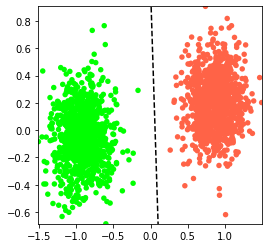

torch.Size([2048, 2])


In [ ]:
with torch.no_grad():
    fig = plt.figure(figsize=(4,4))
    # [TODO] your code
    plt.show()